# DIY Copilot
## Lesson: RAG Evaluation

A coding assistant is only as good as the context it retrieves: if the relevant business rule or guideline is not retrieved, even the best model can only guess. This lesson is intended to show you how to **measure** the retrieval quality, and how different configurations affect it.

During this lesson you will learn how to ...

- evaluate the quality of the retrieval using simple information retrieval metrics
- see what happens if knowledge is missing from the knowledge base
- manipulate the *chunk size* and *top_k* to improve the system

### How the evaluation works

We use an evaluation dataset of typical developer questions about business rules, engineering guidelines and security requirements. For each question we know where the answer is located in the knowledge base: a document and a range of lines (the **ground truth origin**). Sometimes the same knowledge lives in several places (e.g. in a policy *and* in the glossary), so a question can have multiple origins.

A retrieved chunk is **relevant** if it comes from the same document and its lines overlap the ground truth lines.

<div style="font-family: sans-serif; max-width: 900px;">

<table style="width: 100%; border-collapse: separate; border-spacing: 6px;">
<tr>
<td style="background: #dbeafe; border: 1.5px solid #374151; border-radius: 10px; padding: 10px 14px;">
<b>Question:</b><br>"How far in advance can I book a meeting room?"
</td>
<td style="background: #fef3c7; border: 1.5px solid #374151; border-radius: 10px; padding: 10px 14px;">
<b>Ground Truth Origin:</b><br><code>domain/room-booking-policy.md:41-44</code>
</td>
</tr>
</table>

<div style="text-align: center; margin: 6px 0; font-family: monospace;">↓ <code>do_retrieval(top_k=3)</code> ↓</div>

<table style="width: 100%; border-collapse: separate; border-spacing: 6px; text-align: center;">
<tr>
<td style="background: #fecaca; border: 1.5px solid #374151; border-radius: 10px; padding: 10px; vertical-align: top;">
<b>rank 1</b><br><br>
<code>domain/desk-sharing-policy.md:9-16</code><br><br>
<b>not relevant ✗</b><br><small>other document</small>
</td>
<td style="background: #bbf7d0; border: 1.5px solid #374151; border-radius: 10px; padding: 10px; vertical-align: top;">
<b>rank 2</b><br><br>
<code>domain/room-booking-policy.md:28-48</code><br><br>
<b>relevant ✓</b><br><small>lines 28-48 overlap 41-44</small>
</td>
<td style="background: #fecaca; border: 1.5px solid #374151; border-radius: 10px; padding: 10px; vertical-align: top;">
<b>rank 3</b><br><br>
<code>domain/room-booking-policy.md:1-27</code><br><br>
<b>not relevant ✗</b><br><small>no overlap with 41-44</small>
</td>
</tr>
</table>

<div style="background: #ede9fe; border: 1.5px solid #374151; border-radius: 10px; padding: 10px 14px; margin-top: 6px;">
<b>Metrics for this question:</b>
<ul style="line-height: 1.6; margin: 6px 0 0 0;">
<li><b>Hit Rate</b> = <code>1</code> &mdash; ≥1 of the retrieved chunks is relevant</li>
<li><b>Reciprocal Rank</b> = <code>1 / 2 = 0.50</code> &mdash; the first relevant chunk is at rank 2</li>
<li><b>Precision</b> = <code>1 / 3 ≈ 0.33</code> &mdash; 1 of 3 retrieved chunks is relevant</li>
</ul>
</div>

</div>

### Set up the environment

In [1]:
# >>> COLAB SETUP <<<
# Placeholder: clone the workshop repository into the Colab workspace and make `lib` importable.
# When running locally, the following line is sufficient.
import sys
sys.path.append('../../../')

In [2]:
import uuid
from pathlib import Path

import pandas as pd
from chromadb import EphemeralClient
from chromadb.errors import NotFoundError
from langchain_text_splitters import Language, RecursiveCharacterTextSplitter
from pydantic import BaseModel

from lib.constants import EVALUATION_DATA_PATH, KNOWLEDGE_BASE_PATH
from lib.environment import load_environment
from lib.rag import do_batch_embed, do_embed, list_knowledge_base_files, load_file_content

In [3]:
# Configure pandas display options
pd.set_option("max_colwidth", None)

In [4]:
# Set defaults for retrieval
DEFAULT_TOP_K = 3
DEFAULT_CHUNK_OVERLAP = 100
DEFAULT_CHUNK_SIZE = 1000

In [5]:
# This will be the chromadb client we use for the knowledge base. The EphemeralClient keeps everything in memory.
chromadb_client = EphemeralClient()

### Configure the models

In [6]:
# We will only evaluate the retrieval, therefore we only need an embedding model
EMBEDDING_MODEL_ID = load_environment()["embedding_model"]
print(f"Embedding model: {EMBEDDING_MODEL_ID}")

Embedding model: gemini/gemini-embedding-001


### Define the building blocks
For the evaluation we need to know where each chunk comes from. Therefore we store the **document** and the **line range** of each chunk as metadata.

In [7]:
# For the evaluation we need metadata. This function additionally returns the lines each chunk spans.
def do_chunk(text: str, file_name: str, chunk_size: int, chunk_overlap: int) -> tuple[list[str], list[tuple[int, int]]]:
    """Splits the text into chunks and maps them to the lines they span.

    Parameters
    ----------
    text : str
        The text to split
    file_name : str
        The name of the file; its extension determines the splitter
    chunk_size : int
        The size of the chunks
    chunk_overlap : int
        The overlap between the chunks

    Returns
    -------
    tuple[list[str], list[tuple[int, int]]]
        The chunks, and for each chunk its (start_line, end_line) - 1-based and inclusive.
    """
    language = {".py": Language.PYTHON, ".md": Language.MARKDOWN}.get(Path(file_name).suffix)
    if language is None:
        splitter = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=chunk_overlap)
    else:
        splitter = RecursiveCharacterTextSplitter.from_language(
            language=language, chunk_size=chunk_size, chunk_overlap=chunk_overlap
        )
    chunks = splitter.split_text(text)

    line_ranges = []
    search_from = 0
    for chunk in chunks:
        # Search from the position of the previous chunk, so identical chunks get distinct positions
        start_index = text.find(chunk, search_from)
        if start_index == -1:  # the splitter may strip whitespace; fall back to a global search
            start_index = text.find(chunk)
        end_index = start_index + len(chunk)
        start_line = text.count("\n", 0, start_index) + 1
        end_line = text.count("\n", 0, end_index) + 1
        line_ranges.append((start_line, end_line))
        search_from = start_index + 1

    return chunks, line_ranges

In [8]:
# Since we now store metadata in the knowledge base, we need to update the fetching function in order to
# return the metadata as well. We use the pydantic library to define the chunk model.
class Metadata(BaseModel):
    """Represents the metadata of a chunk stored in the knowledge base."""
    source: str
    start_line: int
    end_line: int


class FetchedChunk(BaseModel):
    """Represents a chunk fetched from the knowledge base."""
    chunk: str
    metadata: Metadata


# Building Block "Top-k Fetching": Get the k semantically closest chunks to the user input from the knowledge base
def do_top_k_fetching(user_input_embedding: list[float], top_k: int) -> list[FetchedChunk]:
    """Fetches the k semantically closest chunks to the user input from the knowledge base.

    Parameters
    ----------
    user_input_embedding : list[float]
        The embedding of the user input
    top_k : int
        The number of semantically closest chunks to be fetched

    Returns
    -------
    list[FetchedChunk]
        The fetched chunks with their metadata
    """
    chromadb_collection = chromadb_client.get_collection(name="default")
    query_result = chromadb_collection.query(query_embeddings=[user_input_embedding], n_results=top_k)
    return [
        FetchedChunk(chunk=chunk, metadata=Metadata(**metadata))
        for chunk, metadata in zip(query_result["documents"][0], query_result["metadatas"][0])
    ]

In [9]:
# Building Block "Knowledge base": Store embeddings and the corresponding content in a vector store
def persist_embeddings(chunks: list[str], embeddings: list[list[float]], metadatas: list[dict]) -> None:
    """Persists chunks, embeddings and metadata in the knowledge base.

    Parameters
    ----------
    chunks : list[str]
        The chunks to be persisted.
    embeddings : list[list[float]]
        The corresponding embeddings to be persisted.
    metadatas : list[dict]
        The corresponding metadata to be persisted.
    """
    # hnsw:search_ef ensures deterministic results (see https://github.com/chroma-core/chroma/issues/2675)
    chromadb_collection = chromadb_client.get_or_create_collection(name="default", metadata={"hnsw:search_ef": 50})
    ids = [str(uuid.uuid4()) for _ in chunks]
    chromadb_collection.add(ids=ids, documents=chunks, embeddings=embeddings, metadatas=metadatas)

In [10]:
# We need to update the ingestion in order to store the file and lines of each chunk
def do_ingestion(file_names: list[str], chunk_size: int = DEFAULT_CHUNK_SIZE, verbose: bool = False) -> None:
    """Ingests a list of documents. The knowledge base is cleared first.

    Parameters
    ----------
    file_names : list[str]
        The paths of the documents to be ingested, relative to the root of the knowledge base
    chunk_size : int, optional [default: DEFAULT_CHUNK_SIZE]
        The desired chunk size
    verbose : bool, optional [default: False]
        Whether to print details of the ingestion process or not
    """
    # Check chunk_size in order to avoid too many chunks
    if chunk_size < 200:
        raise ValueError("chunk_size must be at least 200")

    try:
        chromadb_client.delete_collection(name="default")
    except NotFoundError:
        pass  # When running this the first time, there is no collection yet

    all_chunks, all_metadatas = [], []
    for file_name in file_names:
        file_content = load_file_content(KNOWLEDGE_BASE_PATH / file_name)
        chunks, line_ranges = do_chunk(file_content, file_name, chunk_size=chunk_size, chunk_overlap=DEFAULT_CHUNK_OVERLAP)
        all_chunks.extend(chunks)
        all_metadatas.extend(
            {"source": file_name, "start_line": start, "end_line": end} for start, end in line_ranges
        )
        if verbose:
            print(f"Loaded {len(chunks):>3} chunks from {file_name}")

    # Embed all chunks together to save requests (free tier rate limits!)
    embeddings = do_batch_embed(all_chunks, EMBEDDING_MODEL_ID)
    persist_embeddings(all_chunks, embeddings, all_metadatas)
    print(f"Added {len(all_chunks)} chunks from {len(file_names)} documents to the knowledge base")

In [11]:
# We will only evaluate the retrieval, since this is the most important part of the pipeline.
# In a real world scenario, we would also evaluate the generation, e.g. using LLM-based metrics.
def do_retrieval(user_input: str, top_k: int = DEFAULT_TOP_K) -> list[FetchedChunk]:
    """Retrieves the k semantically closest chunks to the user input from the knowledge base.

    Parameters
    ----------
    user_input : str
        The user input to be used for the retrieval
    top_k : int, optional [default: DEFAULT_TOP_K]
        The number of semantically closest chunks to be fetched
    Returns
    -------
    list[FetchedChunk]
        The fetched chunks
    """
    # do_embed from lib.rag caches the embeddings, so repeated evaluations don't cost extra requests
    user_input_embedding = do_embed(user_input, EMBEDDING_MODEL_ID)
    return do_top_k_fetching(user_input_embedding, top_k=top_k)

### Prepare the knowledge base
To see how missing knowledge affects the retrieval, we start by ingesting **only the domain documents** of the business departments – no engineering guidelines and no security requirements.

In [12]:
ALL_FILES = list_knowledge_base_files(KNOWLEDGE_BASE_PATH)
DOMAIN_FILES = [f for f in ALL_FILES if f.startswith("domain/")]

print(f"{len(DOMAIN_FILES)} domain documents, {len(ALL_FILES)} documents in total")
do_ingestion(file_names=DOMAIN_FILES)

4 domain documents, 11 documents in total
Added 12 chunks from 4 documents to the knowledge base


### Ingested metadata

In [13]:
# Let's have a close look at the metadata
fetched_chunks = do_retrieval(user_input="How far in advance can I book a meeting room?")

print(f"Fetched {len(fetched_chunks)} chunks from the knowledge base")
for chunk in fetched_chunks:
    print(f"Metadata: {chunk.metadata}")
    print(f"Chunk:\n{chunk.chunk}\n")

Fetched 3 chunks from the knowledge base
Metadata: source='domain/room-booking-policy.md' start_line=28 end_line=50
Chunk:
### 2.2 Duration

A booking lasts at least 15 minutes and at most **4 hours**. Rooms cannot be
blocked for a whole day by a single booking. Workshops that need a room for a
full day are booked by the facility team as several consecutive bookings –
please send a request to the facility team at least one week in advance.

### 2.3 Business hours

Rooms can be booked from **Monday to Friday between 07:00 and 20:00** (Berlin
time). A booking must start and end on the same day. There are no bookings on
weekends; for weekend events contact the facility team.

### 2.4 Booking in advance

Rooms can be booked at most **60 days in advance**. Bookings further in the
future are not possible, because the room plan may change (e.g. renovations).

## 3. Choosing the right room

### 3.1 Capacity

The number of attendees must not exceed the number of seats of the room.

Metadata: so

### Metrics
Matching the *text of the retrieved chunk* with *the text of the ground truth* is difficult, because the chunks have different sizes and boundaries. Metadata is perfect for information retrieval metrics, because we can match the *retrieved metadata* with the *ground truth metadata*.

First, we need a function that decides whether a retrieved chunk is relevant for a ground truth origin like `domain/room-booking-policy.md:41-44`.

In [14]:
def is_relevant(ground_truth_origin: str, metadata: Metadata) -> bool:
    """Checks whether a retrieved chunk overlaps a ground truth origin "file:start-end".

    Parameters
    ----------
    ground_truth_origin : str
        The ground truth origin, e.g. "domain/room-booking-policy.md:41-44"
    metadata : Metadata
        The metadata of the retrieved chunk
    Returns
    -------
    bool
        True if the chunk comes from the same document and the line ranges overlap
    """
    source, _, lines = ground_truth_origin.rpartition(":")
    start_line, end_line = (int(line) for line in lines.split("-"))
    return (
        metadata.source == source
        and metadata.start_line <= end_line
        and start_line <= metadata.end_line
    )


def is_any_relevant(ground_truth: list[str], metadata: Metadata) -> bool:
    """Checks whether a retrieved chunk is relevant for any of the ground truth origins."""
    return any(is_relevant(origin, metadata) for origin in ground_truth)

In [15]:
# Let's test it. Try it yourself with different values
chunk_metadata = Metadata(source="domain/room-booking-policy.md", start_line=28, end_line=48)
print(is_relevant("domain/room-booking-policy.md:41-44", chunk_metadata))   # overlap -> True
print(is_relevant("domain/room-booking-policy.md:91-98", chunk_metadata))   # no overlap -> False
print(is_relevant("domain/desk-sharing-policy.md:41-44", chunk_metadata))   # other document -> False

True
False
False


#### Hit Rate
Hit Rate is an information retrieval metric that measures whether at least one relevant result (*ground truth chunk*) appears in a list of search results (*retrieved chunks*). If there is at least one relevant item, the hit rate is 1; if there are none, it is 0. It simply checks for the presence of any relevant result, regardless of its position.

In [16]:
# Function to calculate the hit rate
def calculate_hit_rate(ground_truth: list[str], retrieved: list[Metadata]) -> int:
    for metadata in retrieved:
        if is_any_relevant(ground_truth, metadata):
            return 1
    return 0

In [17]:
# Let's test Hit Rate. Try it yourself with different values
ground_truth = ["domain/room-booking-policy.md:52-59", "domain/glossary.md:19-19"]
retrieved = [
    Metadata(source="domain/meeting-rooms-berlin.md", start_line=12, end_line=25),
    Metadata(source="domain/room-booking-policy.md", start_line=46, end_line=60),
]
print(f"Hit Rate: {calculate_hit_rate(ground_truth, retrieved)}")

Hit Rate: 1


#### Reciprocal Rank
Reciprocal Rank is an information retrieval metric that measures how soon the first relevant result (*ground truth chunk*) appears in a list of search results (*retrieved chunks*). It is calculated as the inverse (1 divided by the rank) of the position of the first relevant result. For example, if the first relevant result is at position 3, the reciprocal rank is 1/3. If the retrieved chunks do not contain any relevant chunk, the reciprocal rank is 0.

In [18]:
# Function to calculate the reciprocal rank
def calculate_reciprocal_rank(ground_truth: list[str], retrieved: list[Metadata]) -> float:
    for rank, metadata in enumerate(retrieved, start=1):
        if is_any_relevant(ground_truth, metadata):
            return 1 / rank
    return 0.0

In [19]:
# Let's test Reciprocal Rank. Try it yourself with different values
print(f"Reciprocal Rank: {calculate_reciprocal_rank(ground_truth, retrieved)}")

Reciprocal Rank: 0.5


#### Precision
Precision is an information retrieval metric that measures the proportion of retrieved results that are actually relevant. It is calculated as the number of relevant results divided by the total number of results returned (*top-k*). For example, if 1 out of 4 retrieved chunks is relevant, the precision is 0.25 (25%).

In [20]:
# Function to calculate the precision
def calculate_precision(ground_truth: list[str], retrieved: list[Metadata]) -> float:
    top_k = len(retrieved)
    if top_k == 0:
        return 0.0
    relevant_count = sum(1 for metadata in retrieved if is_any_relevant(ground_truth, metadata))
    return relevant_count / top_k

In [21]:
# Let's test Precision. Try it yourself with different values
print(f"Precision: {calculate_precision(ground_truth, retrieved)}")

Precision: 0.5


### Evaluation
Measure the current performance of the retrieval.

In [22]:
# Load the test data. Multiple origins of one question are separated by ";"
evaluation_dataframe = pd.read_csv(EVALUATION_DATA_PATH / 'evaluation_dataset.csv')
evaluation_dataframe.head()

,question,ground_truth_origin,ground_truth_answer
0,What is the maximum duration of a single meeting room booking?,domain/room-booking-policy.md:28-33,4 hours (240 minutes); longer workshops are booked by the facility team as several bookings.
1,Can I book a meeting room from 10:10 to 10:50?,domain/room-booking-policy.md:22-26,"No, bookings must start and end on a full quarter hour, e.g. 10:00 to 11:00."
2,Can meeting rooms be booked on Saturdays?,domain/room-booking-policy.md:35-39,"No, only Monday to Friday 07:00-20:00; for weekend events contact the facility team."
3,How far in advance can I book a meeting room?,domain/room-booking-policy.md:41-44,At most 60 days.
4,Why am I not allowed to book the Tempelhof room for a 1:1 customer call?,domain/room-booking-policy.md:52-59;domain/glossary.md:19-19,Big room policy: rooms with 12+ seats need at least 4 attendees; use A1-01 or A1-02 which have the same video system.


In [23]:
# Function to run the evaluation for a specific top_k
def evaluate_retrieval(top_k: int = DEFAULT_TOP_K) -> tuple[float, float, float]:
    """Evaluates the retrieval performance using precision, reciprocal rank and hit rate.

    Parameters
    ----------
    top_k : int, optional [default: DEFAULT_TOP_K]
        The number of semantically closest chunks to be fetched
    Returns
    -------
    tuple[float, float, float]
        The mean precision, mean reciprocal rank and mean hit rate
    """
    precisions, reciprocal_ranks, hit_rates = [], [], []

    for _, row in evaluation_dataframe.iterrows():
        question = row['question']
        ground_truth = row['ground_truth_origin'].split(";")

        # Retrieve the chunks and keep only their metadata
        retrieved = [chunk.metadata for chunk in do_retrieval(question, top_k=top_k)]

        precisions.append(calculate_precision(ground_truth, retrieved))
        reciprocal_ranks.append(calculate_reciprocal_rank(ground_truth, retrieved))
        hit_rates.append(calculate_hit_rate(ground_truth, retrieved))

    n = len(evaluation_dataframe)
    return sum(precisions) / n, sum(reciprocal_ranks) / n, sum(hit_rates) / n

In [24]:
# Measure the performance of the retrieval
top_k = 3

mean_precision, mean_reciprocal_rank, mean_hit_rate = evaluate_retrieval(top_k=top_k)

print(f"Average Precision:       {mean_precision:.2f}")
print(f"Average Reciprocal Rank: {mean_reciprocal_rank:.2f}")
print(f"Average Hit Rate:        {mean_hit_rate:.2f}")

Average Precision:       0.15
Average Reciprocal Rank: 0.36
Average Hit Rate:        0.41


### Ingest the engineering and security documents
Many questions of developers are not about business rules, but about *how* we build software: coding and API guidelines, testing standards, security and data protection requirements. Let's add these documents to the knowledge base.

In [25]:
do_ingestion(file_names=ALL_FILES)

Added 36 chunks from 11 documents to the knowledge base


### Exercise 01: Evaluate RAG (again)
The initial performance of the retrieval was quite low. A possible explanation might be that many answers are in the engineering and security documents, which we did not ingest. Now that we ingested all documents, it is your task to measure the performance again.

In [26]:
# TODO: Evaluate the retrieval performance with all documents
mean_precision, mean_reciprocal_rank, mean_hit_rate = evaluate_retrieval(top_k=top_k)

# TODO: Print the results
print(f"Average Precision:       {mean_precision:.2f}")
print(f"Average Reciprocal Rank: {mean_reciprocal_rank:.2f}")
print(f"Average Hit Rate:        {mean_hit_rate:.2f}")

Average Precision:       0.33
Average Reciprocal Rank: 0.87
Average Hit Rate:        0.97


### Exercise 02: Optimize RAG
Now that we know how the retrieval performs, we should improve it. It is your task to improve the performance by manipulating two variables: *top-k* and *chunk size*. Keep in mind that you have to run the ingestion pipeline again as soon as you change the *chunk size*. Try to find reasons why the metrics increase/decrease the way they do!

In [27]:
# TODO: Find the optimal configuration
# Be careful: Do not set the chunk_size below 200, otherwise you get a lot of chunks
chunk_size = 1000   # TODO: Set the chunk size
top_k = 3           # TODO: Set the top_k

do_ingestion(file_names=ALL_FILES, chunk_size=chunk_size)

mean_precision, mean_reciprocal_rank, mean_hit_rate = evaluate_retrieval(top_k=top_k)

print(f"Average Precision:       {mean_precision:.2f}")
print(f"Average Reciprocal Rank: {mean_reciprocal_rank:.2f}")
print(f"Average Hit Rate:        {mean_hit_rate:.2f}")

[retry] rate limit reached, waiting 17s (attempt 1/5) ...
[retry] rate limit reached, waiting 58s (attempt 2/5) ...
Added 36 chunks from 11 documents to the knowledge base
Average Precision:       0.33
Average Reciprocal Rank: 0.87
Average Hit Rate:        0.97


### Learnings
* Missing knowledge can't be retrieved – make sure the knowledge base contains all the rules your assistant has to follow.
* Increasing the chunk size can lead to better performance, because a chunk contains more context (e.g. a whole section).
* At some point large chunks lead to worse retrieval, since the semantic meaning of the chunk gets diluted – and every retrieved chunk fills up the context window.
* Increasing top-k increases the Hit Rate, but decreases the Precision. This becomes a problem in the generation step (too much irrelevant context for the model).
* Since our knowledge base is small, a few large chunks already cover big parts of it. Keep this in mind: in a real company wiki the effects are much stronger.

In [28]:
# Systematic comparison of chunk sizes and top_k. This takes a few minutes.
# The question embeddings are cached, so only the ingestion costs API requests.
mean_hit_rates, mean_precisions, mean_reciprocal_ranks = [], [], []
chunk_sizes_all, top_ks_all = [], []

# Each new chunk costs one embedding request (free tier: 100 per minute, 1000 per day).
# Embeddings are cached, so a chunk size you already ingested costs nothing the second time.
# Still, we only compare a few chunk sizes.
chunk_sizes = [300, 500, 1000, 2000]
top_ks = [1, 3, 5, 10]

for chunk_size in chunk_sizes:
    do_ingestion(file_names=ALL_FILES, chunk_size=chunk_size)

    for top_k in top_ks:
        mean_precision, mean_reciprocal_rank, mean_hit_rate = evaluate_retrieval(top_k=top_k)
        mean_hit_rates.append(mean_hit_rate)
        mean_precisions.append(mean_precision)
        mean_reciprocal_ranks.append(mean_reciprocal_rank)
        chunk_sizes_all.append(chunk_size)
        top_ks_all.append(top_k)

[retry] rate limit reached, waiting 52s (attempt 1/5) ...
[retry] rate limit reached, waiting 52s (attempt 1/5) ...
[retry] rate limit reached, waiting 52s (attempt 1/5) ...
Added 251 chunks from 11 documents to the knowledge base
[retry] rate limit reached, waiting 52s (attempt 1/5) ...
[retry] rate limit reached, waiting 52s (attempt 1/5) ...
Added 151 chunks from 11 documents to the knowledge base
[retry] rate limit reached, waiting 52s (attempt 1/5) ...
Added 76 chunks from 11 documents to the knowledge base
[retry] rate limit reached, waiting 52s (attempt 1/5) ...
Added 47 chunks from 11 documents to the knowledge base
Added 36 chunks from 11 documents to the knowledge base
[retry] rate limit reached, waiting 51s (attempt 1/5) ...
Added 26 chunks from 11 documents to the knowledge base
Added 19 chunks from 11 documents to the knowledge base


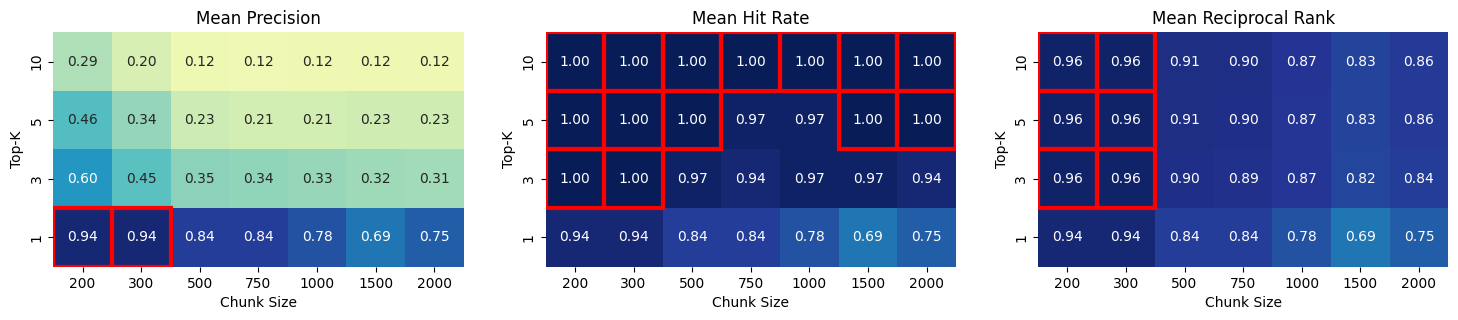

In [29]:
# Visualize the results
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.DataFrame({
    'chunk_size': chunk_sizes_all,
    'top_k': top_ks_all,
    'mean_precision': mean_precisions,
    'mean_hit_rate': mean_hit_rates,
    'mean_reciprocal_rank': mean_reciprocal_ranks,
})


def highlight_best(ax, pivot_df):
    """Draws a red border around every cell holding the max value of the heatmap."""
    max_val = pivot_df.values.max()
    for r in range(pivot_df.shape[0]):
        for c in range(pivot_df.shape[1]):
            if pivot_df.iat[r, c] == max_val:
                ax.add_patch(patches.Rectangle((c, r), 1, 1, fill=False, edgecolor='red', lw=3))


plt.figure(figsize=(18, 6))
for i, (metric, title) in enumerate([
    ('mean_precision', 'Mean Precision'),
    ('mean_hit_rate', 'Mean Hit Rate'),
    ('mean_reciprocal_rank', 'Mean Reciprocal Rank'),
], start=1):
    plt.subplot(1, 3, i)
    heatmap_data = data.pivot(index='top_k', columns='chunk_size', values=metric)
    ax = sns.heatmap(heatmap_data, annot=True, cmap="YlGnBu", fmt=".2f", vmin=0, vmax=1, square=True, cbar=False)
    highlight_best(ax, heatmap_data)
    plt.title(title)
    plt.xlabel('Chunk Size')
    plt.ylabel('Top-K')
    plt.gca().invert_yaxis()

plt.show()